# LTB 12→60개월: 부품 수요 학습 구성의 영향

## 요약

부품 수요만으로 만든 평가 부품 1,350개에서, 학습 구성을 균형 있게 바꾸자 합성 관측은 하락했는데 예측은 상승한 경우가 줄었습니다. 하락형 450개 중 K=3은 **428 → 95개**, 첫해 비중 직접 예측은 **360 → 78개**입니다.
전체 월별 WAPE는 균등 배분(55.86%)이 가장 낮았습니다. 방향 개선과 월별 절대 수량 개선은 별개입니다.

## 질문과 비교 설계

같은 부품 수요 평가셋에 대해 학습의 하락·유지·상승 비율만 바꾸면, 하락하는 부품에 상승 곡선을 붙이는 오류가 줄어드는지 봅니다. 부품 월별 수요만 생성하고, 다른 업무 데이터·변수는 생성하거나 사용하지 않습니다.

- 가상 적용월 9개에 하락·유지·상승 유형을 각각 150개씩 생성합니다. 한 부품의 잠재 추세는 완만하게 변하며, 전환 지연·부품별 규모·계절성·잡음이 있습니다. 적용 전 12개월 수요가 미래 패턴의 힌트를 줄 수 있지만, 같은 유형도 입력 패턴이 다르고 서로 다른 유형끼리도 입력 패턴이 겹칩니다.
- 2019년 1~3월은 별도 평가월입니다. 각 평가월 전에 적용 후 60개월 관측이 끝난 부품만 학습에 씁니다. 모든 모델이 같은 평가 부품을 채점합니다.
- 성숙한 적용월마다 150개씩 뽑습니다. **균형 학습**은 하락/유지/상승 50/50/50개, **상승 편향 학습**은 15/30/105개입니다. 각 적용월·유형 안에서 무작위 순서를 고정한 뒤 앞에서 뽑아, 데이터 풀과 선택 규칙을 공유합니다.
- 예측 입력은 적용 전 12개월의 수요만입니다. 패턴 라벨은 학습 표본의 구성을 정하고 평가를 나눠 보는 데만 씁니다. 유형, 부품 ID, 적용월은 모델에 전달하지 않습니다. 평가의 이후 수요는 점수를 계산할 때만 사용합니다.
- 부품별 예측 총량은 직전 12개월의 월평균 × 60입니다. 균등 배분, K=3, 첫해 비중 직접 예측을 비교합니다. K=3은 학습의 60개월 비중을 군집화하고 수요 이력만으로 군집을 고릅니다. 첫해 비중 직접 예측은 기존 고정 설정의 릿지 회귀를 사용해 첫 12개월 몫을 추정하고 12개월·48개월 안에서 각각 균등 배분합니다.

## 합성 부품 수요 생성

In [1]:
"""Standalone synthetic monthly part-demand generator for a 12→60 experiment.

Only the part demand trajectory is generated. The three latent pattern labels
are benchmark truth for diagnostic evaluation, not observable model features.
All calendar origins have the same generator and class balance; independently
seeded draws and calendar-month seasonality are the only origin differences.
"""

from numbers import Integral
import re

import numpy as np


DEFAULT_ORIGINS = (
    "2009-01", "2009-02", "2009-03",
    "2014-01", "2014-02", "2014-03",
    "2019-01", "2019-02", "2019-03",
)
PART_PATTERNS = ("decline", "stable", "growth")
HISTORY_MONTHS, FUTURE_MONTHS = 12, 60


def _parse_origin(value):
    if not isinstance(value, str) or not re.fullmatch(r"[0-9]{4}-(0[1-9]|1[0-2])", value):
        raise ValueError("origins must be YYYY-MM strings")
    year, month = map(int, value.split("-"))
    if not 2 <= year <= 9994:
        raise ValueError("origin needs a valid prior year and at least five later calendar years")
    return year, month


def _ar_residual(rng, n):
    """Draw one stationary log-residual path across the history/forecast boundary."""
    spread = rng.uniform(0.06, 0.22)
    phi = rng.uniform(0.22, 0.73)
    err = rng.normal(size=n) * spread * np.sqrt(1.0 - phi**2)
    err[0] = rng.normal(scale=spread)
    for i in range(1, n):
        err[i] += phi * err[i - 1]
    return err - 0.5 * spread**2


def _part_trajectory(rng, pattern, origin_month):
    # Latent level at the last history month is the common boundary anchor.
    n = HISTORY_MONTHS + FUTURE_MONTHS
    months_relative = np.arange(-(HISTORY_MONTHS - 1), FUTURE_MONTHS + 1, dtype=float)
    lead = months_relative[HISTORY_MONTHS:]
    boundary_log_level = rng.normal(np.log(55.0), 0.76)

    # Some parts change regime only well after the origin. Their early trend
    # has much weaker predictive association with the eventual class.
    late_break = rng.random() < 0.30
    direction = {"decline": -1, "stable": 0, "growth": 1}[pattern]
    precursor = (0.005 if late_break else 0.021) * direction
    history_slope = float(np.clip(rng.normal(precursor, 0.027), -0.085, 0.085))
    transition_delay = int(rng.integers(5, 16) if late_break else rng.integers(0, 4))
    relaxing_memory = 0.16 * np.tanh(history_slope * np.minimum(lead, transition_delay + 2) / 0.16)
    if direction < 0:
        long_run_shift = -rng.uniform(0.67, 1.92)
    elif direction > 0:
        long_run_shift = rng.uniform(0.52, 1.44)
    else:
        long_run_shift = rng.uniform(-0.15, 0.15)
    transition_tau = rng.uniform(11.0, 35.0)
    transition_progress = -np.expm1(-np.maximum(lead - transition_delay, 0) / transition_tau)
    drift = np.concatenate((
        history_slope * months_relative[:HISTORY_MONTHS],
        relaxing_memory + long_run_shift * transition_progress,
    ))

    # Same shoulder/seasonal process on both sides; no arbitrary jump at the
    # cutoff and no year-specific change in demand response.
    angle = (origin_month - 2 + months_relative) * (2.0 * np.pi / 12.0)
    seasonal = rng.uniform(0.03, 0.24) * np.cos(angle - rng.uniform(0, 2.0 * np.pi))
    seasonal += rng.uniform(0.0, 0.08) * np.cos(2.0 * angle - rng.uniform(0, 2.0 * np.pi))
    demand = np.exp(boundary_log_level + drift + seasonal + _ar_residual(rng, n))
    return demand[:HISTORY_MONTHS], demand[HISTORY_MONTHS:]


def simulate_part_demand(*, seed=20261124, per_pattern=150, origins=DEFAULT_ORIGINS):
    """Return NumPy arrays for balanced latent demand patterns at each origin.

    `origin`, `part_id`, `pattern` each have shape (N,). Continuous synthetic
    quantities `history` and `future` have shapes (N, 12) and (N, 60), and the
    first future month is the origin. Every origin contains `per_pattern` parts
    of each class. No class labels or parameters are estimated using test data.
    """
    if isinstance(seed, bool) or not isinstance(seed, Integral) or seed < 0:
        raise ValueError("seed must be a nonnegative integer")
    if isinstance(per_pattern, bool) or not isinstance(per_pattern, Integral) or per_pattern < 1:
        raise ValueError("per_pattern must be a positive integer")
    if isinstance(origins, str):
        raise ValueError("origins must be a collection of YYYY-MM strings")
    origins = tuple(origins)
    calendar_keys = [_parse_origin(origin) for origin in origins]
    if not origins or len(set(origins)) != len(origins):
        raise ValueError("origins must be nonempty and distinct")

    n = len(origins) * len(PART_PATTERNS) * int(per_pattern)
    history = np.empty((n, HISTORY_MONTHS), dtype=np.float64)
    future = np.empty((n, FUTURE_MONTHS), dtype=np.float64)
    origin_rows, part_ids, labels = [], [], []
    row = 0
    for origin, (year, month) in zip(origins, calendar_keys):
        # Taking another origin/order does not perturb a given origin's draws.
        origin_seed = np.random.SeedSequence([int(seed), year, month])
        for pattern, pattern_seed in zip(PART_PATTERNS, origin_seed.spawn(len(PART_PATTERNS))):
            for idx, part_seed in enumerate(pattern_seed.spawn(int(per_pattern)), start=1):
                historic, target = _part_trajectory(np.random.default_rng(part_seed), pattern, month)
                history[row], future[row] = historic, target
                origin_rows.append(origin)
                part_ids.append(f"SYN-{origin}-{pattern}-{idx:06d}")
                labels.append(pattern)
                row += 1
    return {
        "origin": np.asarray(origin_rows, dtype=str),
        "part_id": np.asarray(part_ids, dtype=str),
        "pattern": np.asarray(labels, dtype=str),
        "history": history,
        "future": future,
    }


def _smoke_test():
    test = simulate_part_demand(origins=("2014-02", "2019-01"), per_pattern=5)
    assert test["history"].shape == (30, 12) and test["future"].shape == (30, 60)
    assert np.unique(test["part_id"]).size == 30
    assert np.isfinite(test["future"]).all() and (test["future"].sum(axis=1) > 0).all()
    for origin in ("2014-02", "2019-01"):
        rows = test["origin"] == origin
        np.testing.assert_array_equal(np.unique(test["pattern"][rows], return_counts=True)[1], [5, 5, 5])
    reordered = simulate_part_demand(origins=("2019-01", "2014-02"), per_pattern=5)
    for field in test:
        np.testing.assert_array_equal(test[field][:15], reordered[field][15:])




In [2]:
simulated = simulate_part_demand()
assert set(simulated) == {"origin", "part_id", "pattern", "history", "future"}


## 모델과 시간 분할

In [3]:
def _ltb_dev12_selector_features(history):
    total = history.sum(axis=1, keepdims=True)
    profile = np.divide(history, total, where=total > 0, out=np.zeros_like(history))
    recent = np.log1p(history[:, -6:].mean(axis=1))
    previous = np.log1p(history[:, -12:-6].mean(axis=1))
    return np.column_stack((
        profile, np.log1p(history.mean(axis=1)), recent, recent - previous,
        (history == 0).mean(axis=1),
    ))

def fit_k3(history, outcomes, score_history):
    """K=3 shape and history-only selection as in the existing V100 baseline."""
    history = np.asarray(history, dtype=np.float64)
    score_history = np.asarray(score_history, dtype=np.float64)
    total = outcomes.sum(axis=1)
    valid = total > 0
    shares = outcomes[valid] / total[valid, None]
    with threadpool_limits(limits=2):
        labels = KMeans(n_clusters=3, random_state=SEED, n_init=25).fit_predict(shares)
        counts = np.bincount(labels, minlength=3)
        assert (counts >= 20).all()
        centers = np.stack([shares[labels == label].mean(axis=0) for label in range(3)])
        forest = RandomForestClassifier(n_estimators=48, max_depth=6, min_samples_leaf=8,
            random_state=SEED, n_jobs=2).fit(_ltb_dev12_selector_features(history[valid]), labels)
        assigned = forest.predict(_ltb_dev12_selector_features(score_history))
    return centers[assigned], counts.tolist()

import numpy as np


FEATURES = ("log_mean", "log_growth_6m", "log_trend", "log_volatility", "zero_fraction", "peak_position")
RIDGE_LAMBDA = 0.10


def history_features(history):
    """Compute features strictly from offsets -12 through -1."""
    history = np.asarray(history, dtype=float)
    if history.ndim != 2 or history.shape[1] != 12:
        raise ValueError("A complete 12-month history is required")
    if not np.isfinite(history).all() or np.any(history < 0):
        raise ValueError("Demand must be finite and nonnegative")
    log_demand = np.log1p(history)
    time = np.arange(12) - 5.5
    smoothed = np.lib.stride_tricks.sliding_window_view(history, 3, axis=1).mean(axis=-1)
    return np.column_stack((
        np.log1p(history.mean(axis=1)),
        np.log1p(history[:, 6:].mean(axis=1)) - np.log1p(history[:, :6].mean(axis=1)),
        log_demand @ time / (time @ time),
        log_demand.std(axis=1),
        (history == 0).mean(axis=1),
        -1 - np.argmax(smoothed[:, ::-1], axis=1),
    ))


def predict_first_year_share(train_history, train_future, evaluation_history):
    """Weighted ridge on the first-year / 60-month actual share of training parts."""
    train = history_features(train_history)
    evaluation = history_features(evaluation_history)
    train_future = np.asarray(train_future, dtype=float)
    if train_future.shape != (len(train), 60):
        raise ValueError("Expected one complete 60-month outcome per training history")
    if not np.isfinite(train_future).all() or np.any(train_future < 0):
        raise ValueError("Training outcomes must be finite and nonnegative")
    target_total = train_future.sum(axis=1)
    # The weight uses only the input-history-based fixed forecast total.
    fixed_total = np.asarray(train_history, dtype=float).sum(axis=1) * 5
    included = (target_total > 0) & (fixed_total > 0)
    if not included.any():
        raise ValueError("No training parts with defined share and positive forecast total")
    y = train_future[included, :12].sum(axis=1) / target_total[included]
    weights = fixed_total[included]
    weights = weights / weights.sum()
    x = train[included]
    center = weights @ x
    scale = np.sqrt(weights @ ((x - center) ** 2))
    scale = np.where(scale > 1e-12, scale, 1)
    z = (x - center) / scale
    y_mean = float(weights @ y)
    weighted_z = z.T * weights
    coefficients = np.linalg.solve(weighted_z @ z + RIDGE_LAMBDA * np.eye(z.shape[1]),
                                   weighted_z @ (y - y_mean))
    raw = y_mean + ((evaluation - center) / scale) @ coefficients
    predicted = np.clip(raw, 0, 1)
    return predicted, {
        "train_used": int(included.sum()),
        "train_excluded": int((~included).sum()),
        "train_weighted_share": y_mean,
        "train_unweighted_share": float(y.mean()),
        "train_parts_over_20pct": int((y > .2).sum()),
        "score_share_min": float(predicted.min()),
        "score_share_median": float(np.median(predicted)),
        "score_share_max": float(predicted.max()),
        "score_clipped": int((raw != predicted).sum()),
    }


def allocate_two_blocks(fixed_total, share):
    """Give the predicted share to M0..M11; use a constant value within each block."""
    fixed_total = np.asarray(fixed_total, dtype=float)
    share = np.asarray(share, dtype=float)
    if fixed_total.ndim != 1 or share.shape != fixed_total.shape:
        raise ValueError("One fixed total and first-year share are required per part")
    if not np.isfinite(fixed_total).all() or np.any(fixed_total < 0):
        raise ValueError("Fixed totals must be finite and nonnegative")
    if not np.isfinite(share).all() or np.any((share < 0) | (share > 1)):
        raise ValueError("First-year shares must be within 0..1")
    by_month = np.concatenate((np.repeat((fixed_total * share / 12)[:, None], 12, axis=1),
                               np.repeat((fixed_total * (1 - share) / 48)[:, None], 48, axis=1)), axis=1)
    np.testing.assert_allclose(by_month.sum(axis=1), fixed_total, rtol=1e-12, atol=1e-9)
    return by_month


In [4]:
import json
import os
from pathlib import Path

import numpy as np
import polars as pl
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from threadpoolctl import threadpool_limits


SEED = 20261124
PATTERNS = ("decline", "stable", "growth")
EVAL = ("2019-01", "2019-02", "2019-03")
MIXES = {"balanced": dict(zip(PATTERNS, (50, 50, 50), strict=True)),
         "skewed": dict(zip(PATTERNS, (15, 30, 105), strict=True))}
MODELS = ("flat_qty", "k3_balanced_qty", "k3_skewed_qty", "direct_balanced_qty", "direct_skewed_qty")
OUTPUT = Path(os.environ.get("LTB_PART_DEMAND_OUT", "/private/tmp/ltb_part_demand_synth_20261124"))


def candidate_orders(simulated):
    """Same fixed random order within each date×pattern for both training mixes."""
    order = {}
    for origin in sorted(set(simulated["origin"]) - set(EVAL)):
        for i, pattern in enumerate(PATTERNS):
            candidates = np.flatnonzero((simulated["origin"] == origin) & (simulated["pattern"] == pattern))
            assert len(candidates) == 150
            rng = np.random.default_rng(np.random.SeedSequence([SEED + 1, int(origin.replace("-", "")), i]))
            order[origin, pattern] = rng.permutation(candidates)
    return order


def build_folds(simulated):
    origins = simulated["origin"]
    last_month = np.asarray(origins, dtype="datetime64[M]") + np.timedelta64(59, "M")
    orders = candidate_orders(simulated)
    forecasts, folds, training_keys = [], [], []
    for origin in EVAL:
        eligible = sorted(set(origins[last_month < np.datetime64(origin, "M")]) - set(EVAL))
        score = np.flatnonzero(origins == origin)
        hist = simulated["history"][score]
        assert len(score) == 450
        fixed = hist.mean(axis=1) * 60
        out = {"flat_qty": np.repeat((fixed / 60)[:, None], 60, axis=1)}
        fold = {"origin": origin, "eligible_origin_count": len(eligible), "eval_n": len(score)}
        for mix, pattern_counts in MIXES.items():
            train = np.concatenate([orders[date, pattern][:pattern_counts[pattern]]
                                    for date in eligible for pattern in PATTERNS])
            assert (last_month[train] < np.datetime64(origin, "M")).all()
            assert not np.intersect1d(train, score).size and len(np.unique(train)) == len(train)
            train_hist, train_future = simulated["history"][train], simulated["future"][train]
            shape, sizes = fit_k3(train_hist, train_future, hist)
            first_year, _ = predict_first_year_share(train_hist, train_future, hist)
            out[f"k3_{mix}_qty"] = fixed[:, None] * shape
            out[f"direct_{mix}_qty"] = allocate_two_blocks(fixed, first_year)
            fold[f"{mix}_counts"] = {p: int((simulated["pattern"][train] == p).sum()) for p in PATTERNS}
            fold[f"{mix}_n"] = len(train)
            fold[f"{mix}_k3_sizes"] = sizes
            fold["train_last_target_month"] = str(last_month[train].max())
            training_keys.extend({"eval_origin": origin, "mix": mix,
                "source_origin": str(origins[j]), "part_id": str(simulated["part_id"][j]),
                "pattern": str(simulated["pattern"][j]), "target_last_month": str(last_month[j])} for j in train)
        assert fold["balanced_n"] == fold["skewed_n"] == len(eligible) * 150
        for quantity in out.values():
            np.testing.assert_allclose(quantity.sum(axis=1), fixed, atol=1e-8, rtol=1e-12)
        forecasts.append((origin, score, fixed, out))
        folds.append(fold)
    return forecasts, folds, training_keys


def compare(frame, origin, pattern):
    sorted_frame = frame.sort("origin", "part_id", "lead_month")
    month1_12 = sorted_frame.filter(pl.col("lead_month") <= 12)
    month49_60 = sorted_frame.filter(pl.col("lead_month") >= 49)
    actual = sorted_frame["observed_qty"].to_numpy().reshape(-1, 60)
    actual_part = actual.sum(axis=1)
    past_dominates = actual[:, :12].sum(axis=1) > actual[:, -12:].sum(axis=1) + 1e-8
    assert (actual_part > 0).all()
    result = {"origin": origin, "pattern": pattern, "parts": len(actual_part), "actual_total": float(actual_part.sum()),
              "actual_first12": float(month1_12["observed_qty"].sum() / actual_part.sum()),
              "actual_last12": float(month49_60["observed_qty"].sum() / actual_part.sum()),
              "observed_decline_n": int(past_dominates.sum())}
    for channel in MODELS:
        predicted = sorted_frame[channel].to_numpy().reshape(-1, 60)
        total = predicted.sum(axis=1)
        pred_increases = predicted[:, -12:].sum(axis=1) > predicted[:, :12].sum(axis=1) + 1e-8
        assert (total > 0).all()
        result[channel] = {"wape": float(np.abs(predicted - actual).sum() / actual_part.sum()),
            "first12": float(month1_12[channel].sum() / total.sum()),
            "last12": float(month49_60[channel].sum() / total.sum()),
            "wrong_direction_n": int(pred_increases.sum()),
            "opposite_when_observed_decline_n": int((past_dominates & pred_increases).sum()),
            "shape_l1": float(np.abs(predicted / total[:, None] - actual / actual_part[:, None]).sum(axis=1).mean()),
        }
    return result


def run_benchmark(simulated):
    OUTPUT.mkdir(mode=0o700, parents=True, exist_ok=True)
    size = len(simulated["part_id"])
    assert len(set(simulated["part_id"])) == size == 4050
    assert set(simulated["pattern"]) == set(PATTERNS)
    for month in set(simulated["origin"]):
        assert all(((simulated["origin"] == month) & (simulated["pattern"] == p)).sum() == 150 for p in PATTERNS)
    assert np.isfinite(simulated["history"]).all() and (simulated["history"] >= 0).all()
    assert np.isfinite(simulated["future"]).all() and (simulated["future"] >= 0).all()
    assert (simulated["history"].sum(axis=1) > 0).all() and (simulated["future"].sum(axis=1) > 0).all()
    forecasts, folds, example_train = build_folds(simulated)
    # Only the scorer reads evaluation outcomes or pattern labels.
    frames = []
    for origin, score, fixed, out in forecasts:
        frames.append(pl.DataFrame({
            "origin": origin, "part_id": np.repeat(simulated["part_id"][score], 60),
            "pattern": np.repeat(simulated["pattern"][score], 60), "lead_month": np.tile(np.arange(1, 61), len(score)),
            "fixed_total": np.repeat(fixed, 60), "observed_qty": simulated["future"][score].ravel(),
            **{key: value.ravel() for key, value in out.items()},
        }))
    result = pl.concat(frames).sort("origin", "part_id", "lead_month")
    assert result.height == 81000
    result.write_parquet(OUTPUT / "part_month.parquet")
    pl.DataFrame(example_train).write_parquet(OUTPUT / "training_membership.parquet")
    pl.DataFrame({key: simulated[key] for key in ("origin", "part_id", "pattern")}).with_columns(
        pl.Series("history_qty", simulated["history"].tolist()),
        pl.Series("future_qty", simulated["future"].tolist()),
    ).write_parquet(OUTPUT / "parts.parquet")
    (OUTPUT / "folds.json").write_text(json.dumps(folds, indent=2), encoding="utf-8")
    summaries = []
    for month in (*EVAL, "pooled"):
        temporal = result if month == "pooled" else result.filter(pl.col("origin") == month)
        for label in ("all", *PATTERNS):
            frame = temporal if label == "all" else temporal.filter(pl.col("pattern") == label)
            summaries.append(compare(frame, month, label))
    (OUTPUT / "metrics.json").write_text(json.dumps(summaries, indent=2), encoding="utf-8")
    curves = result.group_by("pattern", "lead_month").agg(pl.col("observed_qty", *MODELS).sum()).sort(
        "pattern", "lead_month")
    monthly = result.group_by("pattern", "lead_month").agg(
        pl.col("observed_qty").sum().alias("denominator"),
        *[(pl.col(m) - pl.col("observed_qty")).abs().sum().alias(m) for m in MODELS],
    ).with_columns(*(pl.when(pl.col("denominator") > 0).then(pl.col(m) / pl.col("denominator"))
                     .otherwise(None).alias(m) for m in MODELS)).sort("pattern", "lead_month")
    curves.write_parquet(OUTPUT / "curves.parquet")
    monthly.write_parquet(OUTPUT / "monthly_wape.parquet")
    return summaries, curves, folds


In [5]:
summaries, curves, folds = run_benchmark(simulated)
observed_features = history_features(simulated["history"])
history_trend_profile = pl.DataFrame({
    "pattern": simulated["pattern"], "positive_pre_trend": observed_features[:, 2] > 0
}).group_by("pattern").agg(pl.len(), pl.col("positive_pre_trend").mean()).sort("pattern")


## 결과

월별 WAPE는 부품×월 절대오차 합을 합성 관측량 합으로 나눈 값입니다. 첫해 비중은 60개월 총량에서 첫 12개월이 차지하는 비중입니다.
‘반대 방향’은 합성 관측에서 마지막 12개월 수량이 첫 12개월보다 적었는데 **예측은 반대로 많았던 부품**입니다. 균등 배분은 방향이 없는 기준선으로, 반대 방향에 해당하지 않아도 하락을 맞힌 것은 아닙니다.

In [6]:
from IPython.display import display, Markdown
labels = {"flat_qty": "균등 배분", "k3_balanced_qty": "K=3 · 균형", "k3_skewed_qty": "K=3 · 상승 편향",
          "direct_balanced_qty": "첫해 직접 · 균형", "direct_skewed_qty": "첫해 직접 · 상승 편향"}
pnames = {"all": "전체", "decline": "하락형", "stable": "유지형", "growth": "상승형"}
display(pl.DataFrame(folds).select("origin", "train_last_target_month", "eval_n", "balanced_counts", "skewed_counts"))
display(history_trend_profile)
lines = ["| 집단 | 방식 | 월별 WAPE | 첫해 비중(예측/관측) | 반대 방향 부품(대상: 관측 하락) |",
         "| --- | --- | ---: | ---: | ---: |"]
for r in summaries:
    if r["origin"] != "pooled":
        continue
    for m in MODELS:
        model = r[m]
        lines.append(f"| {pnames[r['pattern']]} | {labels[m]} | {model['wape']:.2%} | "
                     f"{model['first12']:.2%} / {r['actual_first12']:.2%} | "
                     f"{model['opposite_when_observed_decline_n']:,} / {r['observed_decline_n']:,} |")
display(Markdown("\n".join(lines)))


origin,train_last_target_month,eval_n,balanced_counts,skewed_counts
str,str,i64,struct[3],struct[3]
"""2019-01""","""2018-12""",450,"{200,200,200}","{60,120,420}"
"""2019-02""","""2019-01""",450,"{250,250,250}","{75,150,525}"
"""2019-03""","""2019-02""",450,"{300,300,300}","{90,180,630}"


pattern,len,positive_pre_trend
str,u32,f64
"""decline""",1350,0.337037
"""growth""",1350,0.665926
"""stable""",1350,0.518519


| 집단 | 방식 | 월별 WAPE | 첫해 비중(예측/관측) | 반대 방향 부품(대상: 관측 하락) |
| --- | --- | ---: | ---: | ---: |
| 전체 | 균등 배분 | 55.86% | 20.00% / 17.25% | 0 / 653 |
| 전체 | K=3 · 균형 | 58.76% | 22.27% / 17.25% | 153 / 653 |
| 전체 | K=3 · 상승 편향 | 59.23% | 13.23% / 17.25% | 621 / 653 |
| 전체 | 첫해 직접 · 균형 | 56.59% | 22.57% / 17.25% | 123 / 653 |
| 전체 | 첫해 직접 · 상승 편향 | 56.61% | 17.29% / 17.25% | 544 / 653 |
| 하락형 | 균등 배분 | 125.77% | 20.00% / 33.22% | 0 / 450 |
| 하락형 | K=3 · 균형 | 129.66% | 24.56% / 33.22% | 95 / 450 |
| 하락형 | K=3 · 상승 편향 | 139.42% | 13.61% / 33.22% | 428 / 450 |
| 하락형 | 첫해 직접 · 균형 | 125.53% | 23.63% / 33.22% | 78 / 450 |
| 하락형 | 첫해 직접 · 상승 편향 | 130.02% | 18.13% / 33.22% | 360 / 450 |
| 유지형 | 균등 배분 | 24.65% | 20.00% / 19.73% | 0 / 203 |
| 유지형 | K=3 · 균형 | 28.88% | 22.50% / 19.73% | 58 / 203 |
| 유지형 | K=3 · 상승 편향 | 31.30% | 13.33% / 19.73% | 193 / 203 |
| 유지형 | 첫해 직접 · 균형 | 25.29% | 22.55% / 19.73% | 45 / 203 |
| 유지형 | 첫해 직접 · 상승 편향 | 25.69% | 17.25% / 19.73% | 184 / 203 |
| 상승형 | 균등 배분 | 54.67% | 20.00% / 12.10% | 0 / 0 |
| 상승형 | K=3 · 균형 | 56.65% | 19.36% / 12.10% | 0 / 0 |
| 상승형 | K=3 · 상승 편향 | 53.87% | 12.68% / 12.10% | 0 / 0 |
| 상승형 | 첫해 직접 · 균형 | 55.68% | 21.38% / 12.10% | 0 / 0 |
| 상승형 | 첫해 직접 · 상승 편향 | 54.42% | 16.37% / 12.10% | 0 / 0 |

In [7]:
def build_part_demand_figure(curves):
    """Compare normalized LTB allocation shapes by synthetic part-demand pattern."""
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import MaxNLocator, PercentFormatter

    pattern = np.asarray(curves["pattern"])
    lead = np.asarray(curves["lead_month"])
    styles = (
        ("observed_qty", "Observed (synthetic)", "#222B36", "-", None, None),
        ("flat_qty", "Flat 12-month mean", "#986214", "--", None, None),
        ("k3_balanced_qty", "K=3 · balanced", "#566F32", (0, (8, 3, 1, 3)), "s", [1, 13, 25, 37, 49]),
        ("k3_skewed_qty", "K=3 · skewed", "#6B803B", ":", "^", [4, 16, 28, 40, 52]),
        ("direct_balanced_qty", "Direct · balanced", "#205F9C", "-.", "o", [7, 19, 31, 43, 55]),
        ("direct_skewed_qty", "Direct · skewed", "#486F9F", (0, (3, 2, 1, 2, 1, 2)), "x", [10, 22, 34, 46, 58]),
    )
    values = {key: np.asarray(curves[key], dtype=float) for key, *_ in styles}
    if any(arr.shape != (180,) for arr in (pattern, lead, *values.values())):
        raise ValueError("Expected three synthetic patterns with 60 monthly rows each")
    labels = (("decline", "Declining demand"), ("stable", "Stable demand"), ("growth", "Growing demand"))
    if set(np.unique(pattern)) != {key for key, _ in labels}:
        raise ValueError("pattern must contain decline, stable, and growth")
    if any(not np.isfinite(v).all() or (v < 0).any() for v in values.values()):
        raise ValueError("Synthetic quantities must be finite and nonnegative")

    data = {}
    zero_total = False
    ymax = 1.0 / 60
    for key, _ in labels:
        idx = np.flatnonzero(pattern == key)
        idx = idx[np.argsort(lead[idx])]
        if not np.array_equal(lead[idx], np.arange(1, 61)):
            raise ValueError(f"Expected one row per lead month 1–60 for {key}")
        shares = {}
        for field, quantities in values.items():
            y = quantities[idx]
            total = y.sum()
            if total > 0:
                shares[field] = y / total
                ymax = max(ymax, shares[field].max())
            else:
                shares[field] = np.full(y.shape, np.nan)
                zero_total = True
        data[key] = lead[idx], shares

    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10}):
        fig, axes = plt.subplots(1, 3, figsize=(15.1, 5.8), sharex=True, sharey=True, facecolor="white")
        fig.subplots_adjust(left=0.086, right=0.978, bottom=0.17, top=0.683, wspace=0.13)
        fig.text(0.086, 0.952, "Synthetic LTB allocation by part-demand pattern",
                 fontsize=19, weight="bold", color="#222B36")
        fig.text(0.086, 0.895, "No sales inputs  |  12 months of history  |  60-month horizon",
                 fontsize=10.5, color="#4A5564")
        handles = []
        for i, (ax, (pattern_name, panel_title)) in enumerate(zip(axes, labels)):
            months, curves = data[pattern_name]
            for key, name, color, ls, marker, positions in styles:
                line, = ax.plot(months, curves[key], label=name, color=color, linestyle=ls,
                                linewidth=2.25 if key == "observed_qty" else 1.84,
                                marker=marker, markevery=positions, markersize=4,
                                markerfacecolor="white", markeredgewidth=1.0)
                if i == 0:
                    handles.append(line)
            ax.set_title(panel_title, loc="left", fontsize=12.5, weight="bold", color="#222B36", pad=8)
            ax.set_xlim(0.5, 60.5)
            ax.set_ylim(0, ymax * 1.1)
            ax.set_xticks([1, 12, 24, 36, 48, 60])
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
            ax.set_axisbelow(True)
            ax.grid(axis="y", color="#DDE3EB", linewidth=0.8)
            ax.tick_params(axis="both", length=3.5, color="#728095", labelcolor="#374151")
            ax.spines[["top", "right"]].set_visible(False)
            ax.spines[["left", "bottom"]].set_color("#9CA8B8")
        axes[0].set_ylabel("Share of each series’ 60-month total", color="#374151")
        fig.supxlabel("Lead month (1 = LTB policy effective month)", x=0.532, y=0.091,
                      fontsize=10.5, color="#374151")
        fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.086, 0.830), borderaxespad=0,
                   ncol=6, frameon=False, handlelength=2.9, columnspacing=1.45)
        footer = "Each curve is normalized separately within its pattern. Synthetic experiment only, not operational evidence."
        if zero_total:
            footer += " Curves with a zero total are omitted."
        fig.text(0.086, 0.029, footer, fontsize=9, color="#4A5564")
    return fig


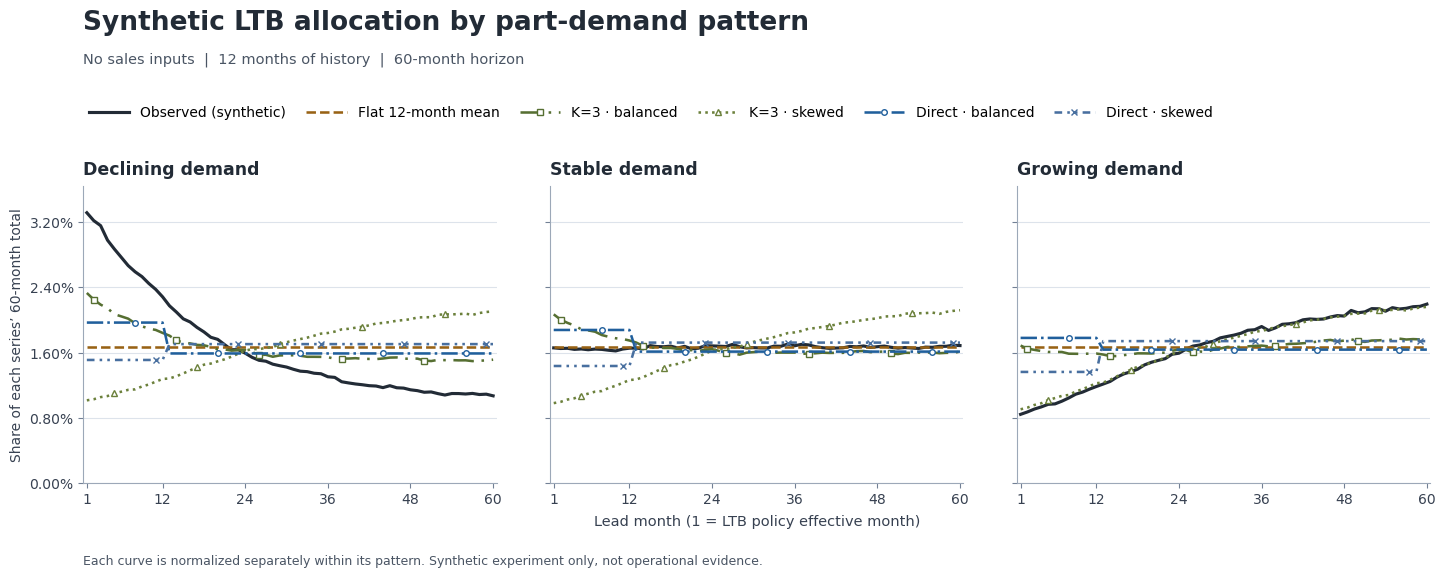

In [8]:
import matplotlib.pyplot as plt
fig = build_part_demand_figure(curves)
fig.savefig(OUTPUT / "part_demand_mix_curves.png", dpi=150, facecolor="white")
display(fig)
plt.close(fig)


## 해석

- 같은 평가 부품에 대해 학습 부품 수, 모델 설정, 총량 산식은 같고 학습 패턴의 비율만 바꿨습니다. 하락형의 합성 첫해 비중은 33.22%였고, K=3은 학습 균형화 후 13.61%에서 24.56%로, 직접 예측은 18.13%에서 23.63%로 가까워졌습니다. 정확한 초기 배분에는 여전히 못 미칩니다.
- 상승형에서는 반대로 균형 학습의 월별 WAPE가 두 학습 방식 모두 커졌습니다. 따라서 1:1:1은 합성 통제 조건이며 운영에 써야 할 최적 비율을 뜻하지 않습니다.
- 모든 예측 방식이 직전 12개월 평균×60을 유지했으므로, 수량 총합이 맞는지를 별도로 개선한 실험이 아닙니다. 월별 절대오차율이 100%를 넘을 수 있습니다.
- 그림은 집단별 예측·관측 총량을 각각 100%로 맞춰 배분 방향만 비교합니다. 합성 생성기의 과거 추세에는 약한 미래 신호가 들어 있으나 겹침과 지연 전환이 있습니다. 운영 데이터에 같은 신호나 효과가 있다고 해석하지 않습니다.